<a href="https://colab.research.google.com/github/daviminati/Trabalho_Des.Aplicacoes_Computacionais/blob/main/Davi_Minati_Elian_Duarte.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Limpeza dos Dados
Nesta etapa, carregamos os dados do arquivo `train.csv`, verificamos a presença de linhas duplicadas e tratamos os valores faltantes (nulos). Atribuímos a mediana para variáveis numéricas e a string 'None' para variáveis categóricas onde a ausência de dado representa uma característica real (ex: ausência de porão ou garagem).

In [ ]:
import pandas as pd
import numpy as np

url_train = 'https://raw.githubusercontent.com/daviminati/house-prices-data/main/train.csv'
df = pd.read_csv(url_train)

url_test = 'https://raw.githubusercontent.com/daviminati/house-prices-data/main/test.csv'
df_test = pd.read_csv(url_test)

# 1. Verificando dados duplicados
print(f"Total de linhas duplicadas: {df.duplicated().sum()}")

# 2. Verificando valores faltantes (nulos)
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("\nTop 5 colunas com mais valores faltantes antes do tratamento:")
print(missing.head())

# Tratamento de valores faltantes
num_cols = df.select_dtypes(include=[np.number]).columns
cat_cols = df.select_dtypes(include=['object']).columns

df[num_cols] = df[num_cols].fillna(df[num_cols].median())
df[cat_cols] = df[cat_cols].fillna('None')

print(f"\nTotal de valores faltantes após a limpeza: {df.isnull().sum().sum()}")

Total de linhas duplicadas: 0

Top 5 colunas com mais valores faltantes antes do tratamento:
PoolQC         1453
MiscFeature    1406
Alley          1369
Fence          1179
MasVnrType      872
dtype: int64

Total de valores faltantes após a limpeza: 0


## 2. Exportação dos Dados Limpos
Após o tratamento inicial das falhas e duplicidades, salvamos o dataframe limpo em um novo arquivo `.csv`.

In [ ]:
df.to_csv('dados_limpos.csv', index=False)
print("Arquivo 'dados_limpos.csv' exportado com sucesso!")

Arquivo 'dados_limpos.csv' exportado com sucesso!


## 3. Classificação de Variáveis (Categóricas e Numéricas)
Separamos as colunas do dataset entre quantitativas (numéricas) e qualitativas (categóricas) para aplicar as técnicas estatísticas corretas em cada tipo de dado.

In [ ]:
categoricos = list(df.select_dtypes(include=['object']).columns)
numericos = list(df.select_dtypes(include=[np.number]).columns)

print(f"Total de variáveis numéricas: {len(numericos)}")
print(f"Total de variáveis categóricas: {len(categoricos)}")

Total de variáveis numéricas: 38
Total de variáveis categóricas: 43


## 4. Medidas de Tendência Central e Dispersão
Utilizamos funções estatísticas para extrair média, desvio padrão, mínimo, mediana e máximo das principais variáveis numéricas, entendendo a distribuição dos dados.

In [ ]:
estatisticas = df[numericos].describe().T[['mean', 'std', 'min', '50%', 'max']]
estatisticas.rename(columns={'50%': 'median'}, inplace=True)
estatisticas.head(10)

,mean,std,min,median,max
Id,730.500000,421.610009,1.0,730.5,1460.0
MSSubClass,56.897260,42.300571,20.0,50.0,190.0
LotFrontage,69.863699,22.027677,21.0,69.0,313.0
LotArea,10516.828082,9981.264932,1300.0,9478.5,215245.0
OverallQual,6.099315,1.382997,1.0,6.0,10.0
OverallCond,5.575342,1.112799,1.0,5.0,9.0
YearBuilt,1971.267808,30.202904,1872.0,1973.0,2010.0
YearRemodAdd,1984.865753,20.645407,1950.0,1994.0,2010.0
MasVnrArea,103.117123,180.731373,0.0,0.0,1600.0
BsmtFinSF1,443.639726,456.098091,0.0,383.5,5644.0


## 5. Gráficos de Dispersão e Correlação
Construímos um gráfico de dispersão relacionando a área habitável acima do solo (`GrLivArea`) com o preço de venda (`SalePrice`). É possível notar visualmente uma clara tendência de correlação positiva.

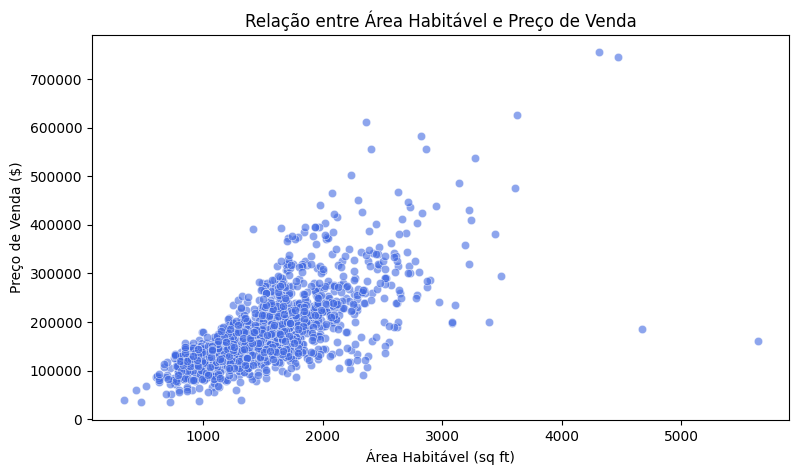

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='GrLivArea', y='SalePrice', alpha=0.6, color='royalblue')
plt.title('Relação entre Área Habitável e Preço de Venda')
plt.xlabel('Área Habitável (sq ft)')
plt.ylabel('Preço de Venda ($)')
plt.show()

## 6. Verificação de Outliers com Boxplot
Analisamos a presença de valores discrepantes (outliers) na variável alvo (`SalePrice`). Observa-se que existem valores mais elevados que fogem do padrão geral (mansões ou imóveis de altíssimo padrão), mas optamos por mantê-los para refletir a realidade do mercado imobiliário.

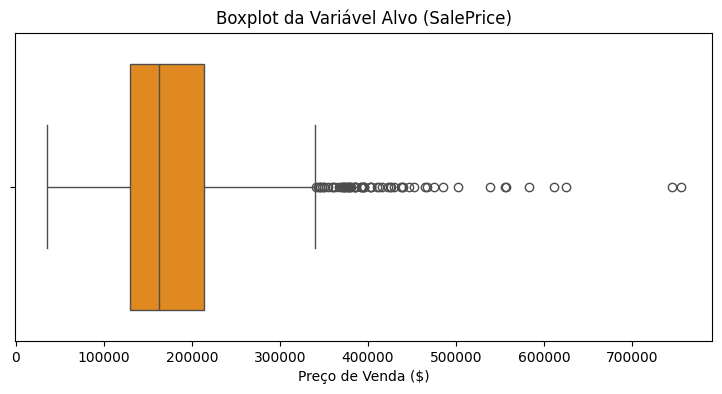

In [ ]:
plt.figure(figsize=(9, 4))
sns.boxplot(x=df['SalePrice'], color='darkorange')
plt.title('Boxplot da Variável Alvo (SalePrice)')
plt.xlabel('Preço de Venda ($)')
plt.show()

## 7. Perguntas aos Dados e Insights por Filtros
Formulamos 5 perguntas analíticas respondidas através de operações de filtragem no Pandas, gerando insights práticos sobre o comportamento dos imóveis:
1. Qual o preço médio de casas com qualidade geral (`OverallQual`) alta ($\ge 8$)?
2. Quantas residências possuem mais de 2 banheiros completos (`FullBath`)?
3. Qual é o preço máximo de venda no bairro `OldTown`?
4. Quantas casas possuem lareira e ar-condicionado central?
5. Qual a área média de lote (`LotArea`) para imóveis construídos após 2000?

In [ ]:
p1 = df[df['OverallQual'] >= 8]['SalePrice'].mean()
p2 = (df['FullBath'] > 2).sum()
p3 = df[df['Neighborhood'] == 'OldTown']['SalePrice'].max()
p4 = len(df[(df['Fireplaces'] > 0) & (df['CentralAir'] == 'Y')])
p5 = df[df['YearBuilt'] > 2000]['LotArea'].mean()

print(f"1. Média de preço (Qualidade >= 8): ${p1:,.2f}")
print(f"2. Imóveis com mais de 2 banheiros: {p2}")
print(f"3. Preço máximo em OldTown: ${p3:,.2f}")
print(f"4. Imóveis com lareira e AC central: {p4}")
print(f"5. Área média de lotes (pós-2000): {p5:,.2f} sq ft")

1. Média de preço (Qualidade >= 8): $305,035.90
2. Imóveis com mais de 2 banheiros: 33
3. Preço máximo em OldTown: $475,000.00
4. Imóveis com lareira e AC central: 756
5. Área média de lotes (pós-2000): 10,025.96 sq ft


## 8. Definição do Objetivo de Aprendizado de Máquina
* **Tipo de Problema:** Regressão (previsão de valor contínuo).
* **Variável Alvo (Target):** `SalePrice`.
* **Variáveis de Entrada (Features):** `OverallQual`, `GrLivArea`, `GarageCars`, `TotalBsmtSF`, `FullBath`, `YearBuilt`.

## 9. Exportação das Variáveis de Interesse
Selecionamos estritamente as colunas definidas no escopo do modelo de Machine Learning e exportamos para um novo arquivo CSV dedicado.

In [ ]:
colunas_interesse = ['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'FullBath', 'YearBuilt', 'SalePrice']
df_interesse = df[colunas_interesse]
df_interesse.to_csv('variaveis_interesse.csv', index=False)
print("Arquivo 'variaveis_interesse.csv' gerado com sucesso!")

Arquivo 'variaveis_interesse.csv' gerado com sucesso!


## 10. Conceituação: Normalização vs. Padronização
* **Normalização (Min-Max Scaling):** Reduz os valores das features para um intervalo fixo entre 0 e 1, útil para algoritmos sensíveis a escalas arbitrárias onde a distribuição não é estritamente Gaussiana.
* **Padronização (Standardization / Z-score):** Re-escala os dados para média igual a 0 e desvio padrão igual a 1, essencial para modelos baseados em gradiente ou distâncias lineares.
* *Referência bibliográfica de apoio:* GERON, Aurélien. *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*. O'Reilly Media.

## 11 e 12. Execução da Normalização / Padronização e Salvamento Final
Aplicamos as transformações matemáticas de normalização e padronização nas variáveis de interesse utilizando o `scikit-learn` e gravamos os arquivos finais em formato `.csv`.

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

features = ['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'FullBath', 'YearBuilt']

# 1. Normalização (Min-Max)
scaler_norm = MinMaxScaler()
df_normalizado = df_interesse.copy()
df_normalizado[features] = scaler_norm.fit_transform(df_interesse[features])

# 2. Padronização (StandardScaler)
scaler_padrao = StandardScaler()
df_padronizado = df_interesse.copy()
df_padronizado[features] = scaler_padrao.fit_transform(df_interesse[features])

# Salvando os arquivos finais
df_normalizado.to_csv('variaveis_normalizadas.csv', index=False)
df_padronizado.to_csv('variaveis_padronizadas.csv', index=False)

print("Arquivos 'variaveis_normalizadas.csv' e 'variaveis_padronizadas.csv' salvos com sucesso!")

Arquivos 'variaveis_normalizadas.csv' e 'variaveis_padronizadas.csv' salvos com sucesso!
